# Paddy Yield Prediction & Variety Recommendation
### Machine Learning Project — B1_Sec_A_Sem_V — Group 2

| Roll No. | Name |
|---|---|
| 2427010043 | Akshat Kumar |
| 2427010049 | Kushal Bajaj |
| 2427010336 | Chirag Sahu |

**Problem Statement:** Develop a hybrid, feature-optimized and decision-support machine learning framework that
1. **identifies the key factors** influencing paddy growth,
2. **predicts rice yield**, and
3. **recommends the most suitable paddy variety** based on agricultural conditions and farmers' preferences.

**Dataset:** M. Subramaniyan, *"Paddy Dataset"*, UCI Machine Learning Repository, 2023. https://doi.org/10.24432/C55W3J

---
### Our workflow (step by step)
1. Import libraries
2. Load the data
3. **Data cleaning** (fix column names, missing values, duplicates, outliers)
4. **Exploratory Data Analysis (EDA)** — understand the data with graphs
5. **Feature optimization** — remove useless / repeated columns
6. Train–test split
7. **Model training** — try 5 models, including our **Hybrid (Stacking) model**
8. **Test performance metrics** (R², MAE, RMSE, MAPE) + cross-validation
9. **Key factors** influencing yield (feature importance)
10. **Decision support** — recommend the best variety for a farmer
11. Save the model & conclusion

## Step 1: Import libraries
We use only well-known Python libraries:
- **pandas / numpy** → handle data
- **matplotlib / seaborn** → draw graphs
- **scikit-learn** → machine learning models and metrics
- **joblib** → save the trained model

In [1]:
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   # avoids a harmless Windows warning
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              ExtraTreesRegressor, StackingRegressor)
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", palette="Blues_d")
plt.rcParams["figure.dpi"] = 110
print("Libraries loaded.")

Libraries loaded.


## Step 2: Load the dataset
The CSV file `paddydataset.csv` must be in the same folder as this notebook.

In [2]:
df = pd.read_csv("paddydataset.csv")
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (2789, 45)


,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,...,Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
0,6,Cuddalore,CO_43,alluvial,150,75.0,dry,120,6,240,...,SW,W,NNW,WSW,72.0,78,88,85,540,35028
1,6,Kurinjipadi,ponmani,clay,150,75.0,wet,120,6,240,...,NW,S,SE,SSE,64.6,85,84,87,600,35412
2,6,Panruti,delux ponni,alluvial,150,75.0,dry,120,6,240,...,ENE,NE,NNE,W,85.0,96,84,79,600,36300
3,6,Kallakurichi,CO_43,clay,150,75.0,wet,120,6,240,...,W,WNW,SE,S,88.5,95,81,84,540,35016
4,6,Sankarapuram,ponmani,alluvial,150,75.0,dry,120,6,240,...,SSE,W,SW,NW,72.7,91,83,81,600,34044


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2789 entries, 0 to 2788
Data columns (total 45 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Hectares                            2789 non-null   int64  
 1   Agriblock                           2789 non-null   object 
 2   Variety                             2789 non-null   object 
 3   Soil Types                          2789 non-null   object 
 4   Seedrate(in Kg)                     2789 non-null   int64  
 5   LP_Mainfield(in Tonnes)             2789 non-null   float64
 6   Nursery                             2789 non-null   object 
 7   Nursery area (Cents)                2789 non-null   int64  
 8   LP_nurseryarea(in Tonnes)           2789 non-null   int64  
 9   DAP_20days                          2789 non-null   int64  
 10  Weed28D_thiobencarb                 2789 non-null   int64  
 11  Urea_40Days                         2789 no

## Step 3: Data cleaning

### 3.1 Clean the column names
Some original column names have extra spaces and long units, e.g. `'Hectares '` (note the space at the end).
We rename them to short, simple names so the code is easier to read.

In [4]:
print("Before:", list(df.columns[:5]))

df.columns = df.columns.str.strip()          # remove extra spaces
df = df.rename(columns={
    "Hectares": "Hectares",
    "Soil Types": "Soil",
    "Seedrate(in Kg)": "Seedrate",
    "LP_Mainfield(in Tonnes)": "LP_Mainfield",
    "Nursery area (Cents)": "Nursery_area",
    "LP_nurseryarea(in Tonnes)": "LP_Nursery",
    "Pest_60Day(in ml)": "Pest_60Day",
    "Trash(in bundles)": "Trash",
    "Paddy yield(in Kg)": "Yield",
})
# remove the unit text like "( in mm)" / "(in Knots)" from the remaining names
df.columns = (df.columns.str.replace(r"\(.*?\)", "", regex=True)
                        .str.strip().str.replace(" ", "_"))

# also remove extra spaces inside text values
for col in df.select_dtypes("object").columns:
    df[col] = df[col].str.strip()

print("After: ", list(df.columns[:5]))
print("\nAll columns:\n", list(df.columns))

Before: ['Hectares ', 'Agriblock', 'Variety', 'Soil Types', 'Seedrate(in Kg)']
After:  ['Hectares', 'Agriblock', 'Variety', 'Soil', 'Seedrate']

All columns:
 ['Hectares', 'Agriblock', 'Variety', 'Soil', 'Seedrate', 'LP_Mainfield', 'Nursery', 'Nursery_area', 'LP_Nursery', 'DAP_20days', 'Weed28D_thiobencarb', 'Urea_40Days', 'Potassh_50Days', 'Micronutrients_70Days', 'Pest_60Day', '30DRain', '30DAI', '30_50DRain', '30_50DAI', '51_70DRain', '51_70AI', '71_105DRain', '71_105DAI', 'Min_temp_D1_D30', 'Max_temp_D1_D30', 'Min_temp_D31_D60', 'Max_temp_D31_D60', 'Min_temp_D61_D90', 'Max_temp_D61_D90', 'Min_temp_D91_D120', 'Max_temp_D91_D120', 'Inst_Wind_Speed_D1_D30', 'Inst_Wind_Speed_D31_D60', 'Inst_Wind_Speed_D61_D90', 'Inst_Wind_Speed_D91_D120', 'Wind_Direction_D1_D30', 'Wind_Direction_D31_D60', 'Wind_Direction_D61_D90', 'Wind_Direction_D91_D120', 'Relative_Humidity_D1_D30', 'Relative_Humidity_D31_D60', 'Relative_Humidity_D61_D90', 'Relative_Humidity_D91_D120', 'Trash', 'Yield']


### 3.2 Check for missing values

In [5]:
missing = df.isnull().sum().sum()
print("Total missing values in the whole dataset:", missing)

Total missing values in the whole dataset: 0


 There are **no missing values**, so we don't need to fill anything.

### 3.3 Remove duplicate rows
Duplicate rows are exact copies. If the same row is in both the training and the testing data, the model is "tested on what it already saw", which gives a falsely high score. So we remove them.

In [6]:
print("Duplicate rows found:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows found: 451
Shape after removing duplicates: (2338, 45)


### 3.4 Check outliers in the target (Yield)
We look at a boxplot of the yield. Points far outside the box would be outliers.

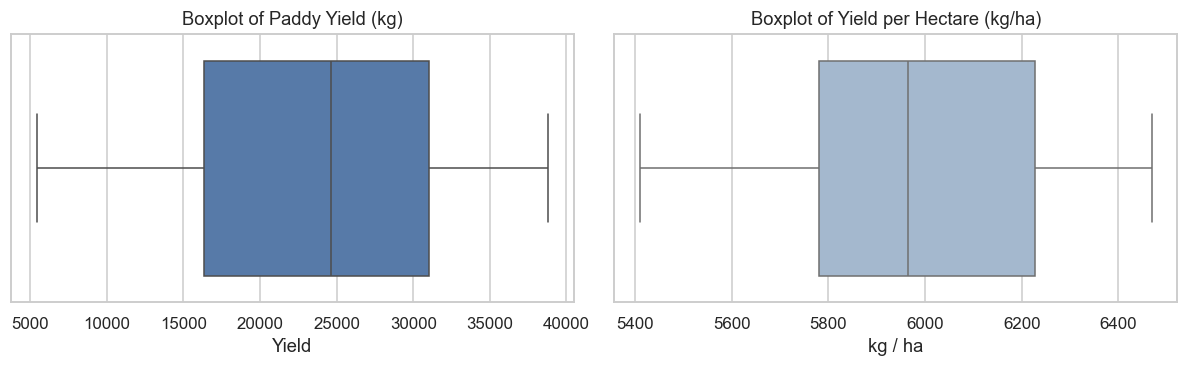

Yield per hectare ranges from 5410 to 6469 kg/ha


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=df["Yield"], ax=ax[0], color="#4a78b5")
ax[0].set_title("Boxplot of Paddy Yield (kg)")
sns.boxplot(x=df["Yield"] / df["Hectares"], ax=ax[1], color="#9db7d5")
ax[1].set_title("Boxplot of Yield per Hectare (kg/ha)"); ax[1].set_xlabel("kg / ha")
plt.tight_layout(); plt.show()

per_ha = df["Yield"] / df["Hectares"]
print(f"Yield per hectare ranges from {per_ha.min():.0f} to {per_ha.max():.0f} kg/ha")

 No extreme outliers. Yield per hectare stays in a realistic range (≈5,400 – 6,500 kg/ha), so we keep all rows.

### 3.5 Look at the categorical (text) columns

In [8]:
for col in ["Agriblock", "Variety", "Soil", "Nursery"]:
    print(col, "→", df[col].value_counts().to_dict())

Agriblock → {'Sankarapuram': 502, 'Kurinjipadi': 401, 'Cuddalore': 364, 'Panruti': 360, 'Chinnasalem': 358, 'Kallakurichi': 353}
Variety → {'ponmani': 895, 'delux ponni': 832, 'CO_43': 611}
Soil → {'clay': 1268, 'alluvial': 1070}
Nursery → {'dry': 1255, 'wet': 1083}


## Step 4: Exploratory Data Analysis (EDA)
We draw graphs to understand what affects the yield.

### 4.1 Distribution of yield

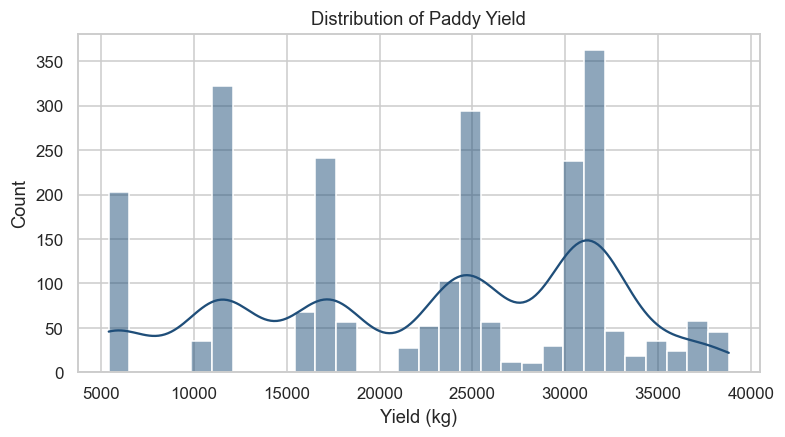

In [9]:
plt.figure(figsize=(8, 4))
sns.histplot(df["Yield"], bins=30, kde=True, color="#1f4e79")
plt.title("Distribution of Paddy Yield"); plt.xlabel("Yield (kg)")
plt.show()

### 4.2 Yield vs Farm Area (Hectares)

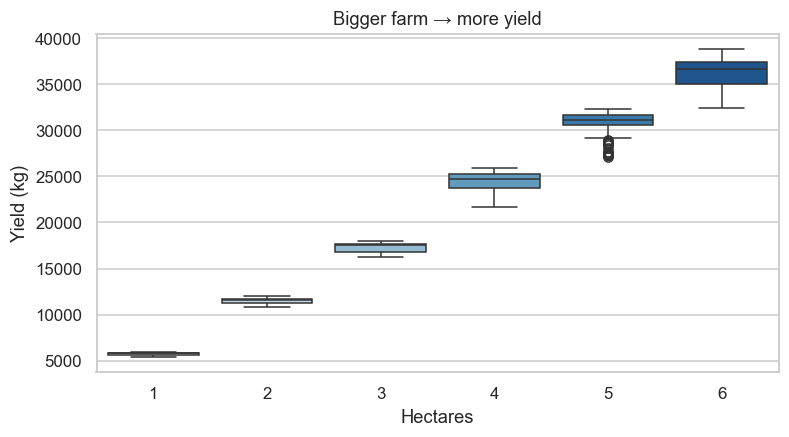

Correlation between Hectares and Yield: 0.994


In [10]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="Hectares", y="Yield", palette="Blues")
plt.title("Bigger farm → more yield"); plt.ylabel("Yield (kg)")
plt.show()
print("Correlation between Hectares and Yield:", round(df["Hectares"].corr(df["Yield"]), 3))

 **Farm area is the strongest factor.** Correlation ≈ 0.99, i.e. yield grows almost in a straight line with area.

### 4.3 Average yield per hectare by Variety, Soil, Nursery and Agriblock

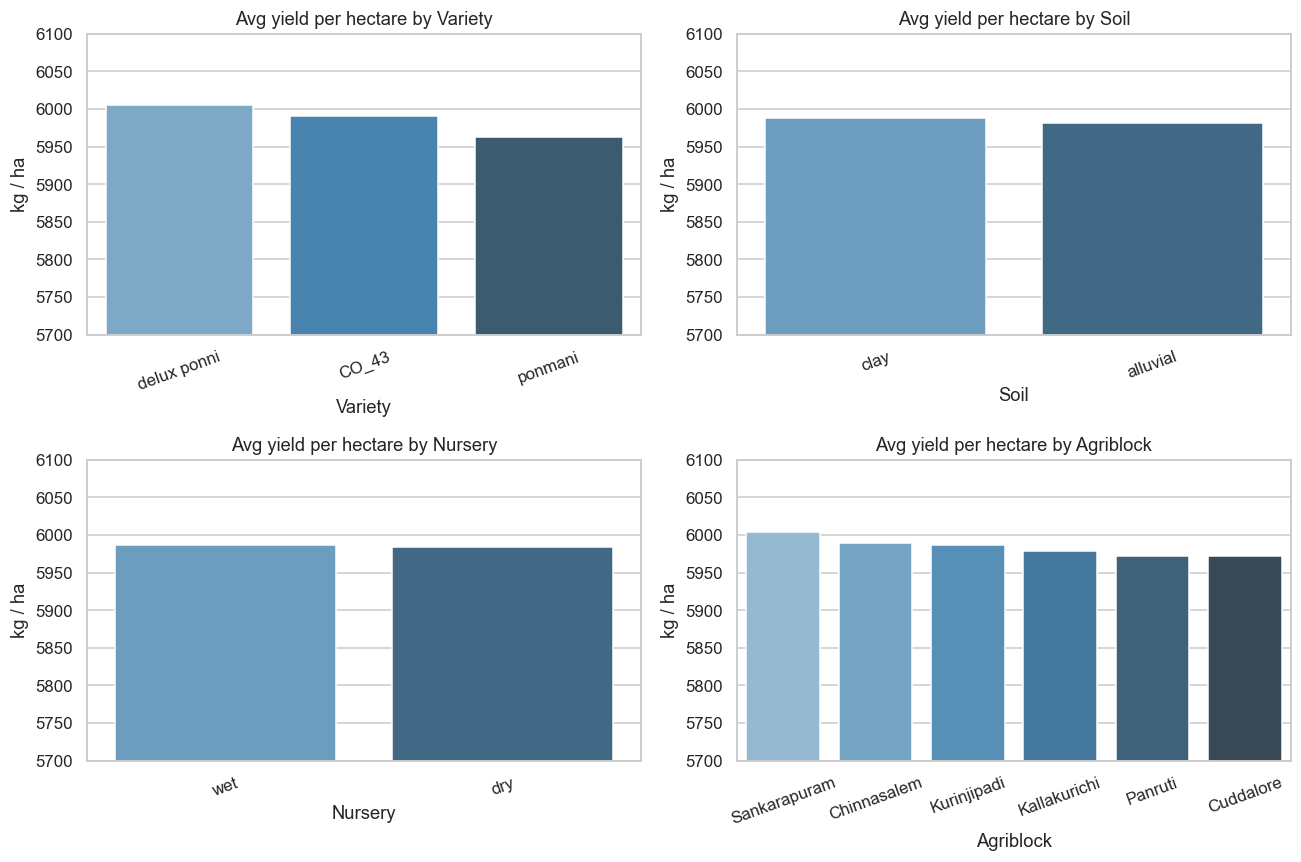

In [11]:
df["Yield_per_ha"] = df["Yield"] / df["Hectares"]   # helper column only for EDA

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ["Variety", "Soil", "Nursery", "Agriblock"]):
    order = df.groupby(col)["Yield_per_ha"].mean().sort_values(ascending=False).index
    sns.barplot(data=df, x=col, y="Yield_per_ha", order=order, ax=ax, palette="Blues_d", errorbar=None)
    ax.set_ylim(5700, 6100)
    ax.set_title(f"Avg yield per hectare by {col}")
    ax.set_ylabel("kg / ha"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

### 4.4 Correlation heatmap (numeric columns)

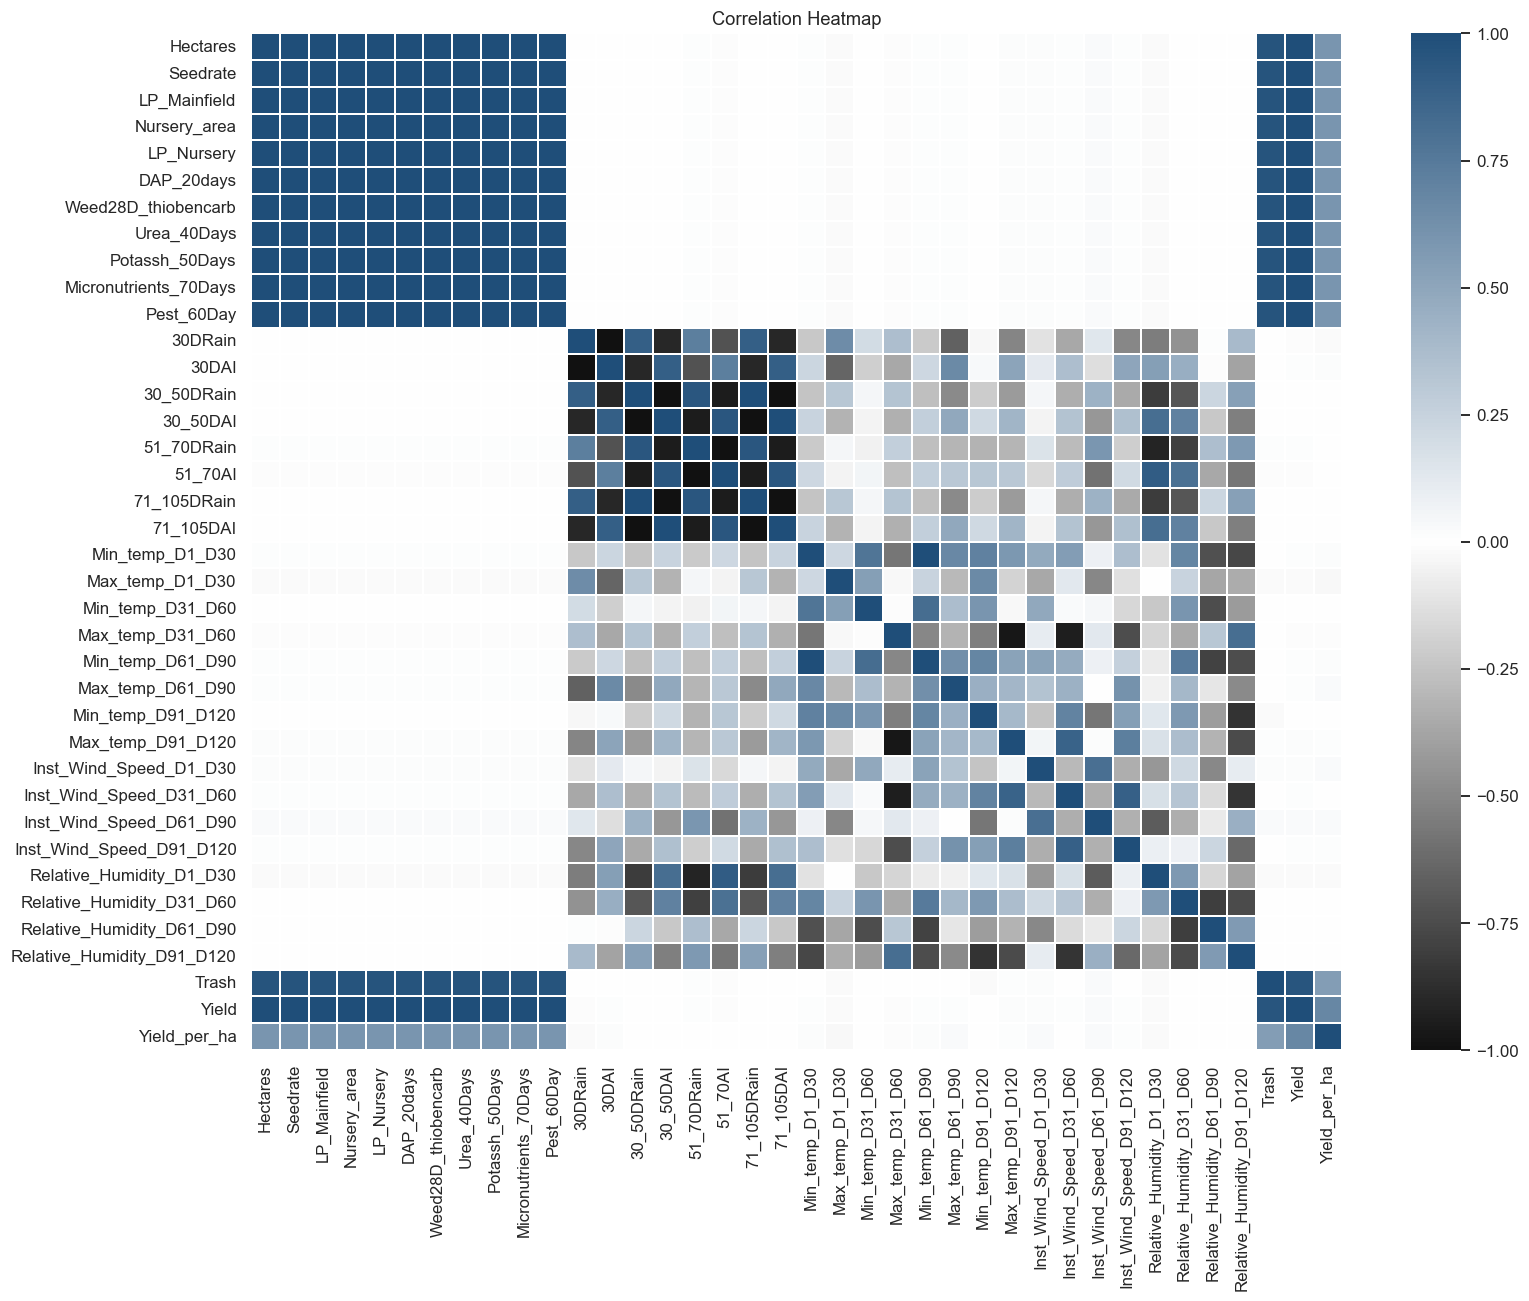

In [12]:
num_cols = df.select_dtypes("number").columns
plt.figure(figsize=(16, 12))
sns.heatmap(df[num_cols].corr(), cmap=LinearSegmentedColormap.from_list("bwb", ["#111111", "#ffffff", "#1f4e79"]), center=0, linewidths=0.3)
plt.title("Correlation Heatmap")
plt.show()

 **Observation:** the top-left block is completely dark green (correlation = 1).
Seed rate, DAP, Urea, Potash, Pesticide etc. are all **calculated from Hectares** (fixed amount per hectare).
They carry the **same information** as Hectares, so they are **repeated (redundant) features**.

## Step 5: Feature optimization
"Feature-optimized" means we keep **only the useful columns**. Fewer, cleaner features make the model faster, simpler and easier to explain, **without losing accuracy**.

We remove three kinds of columns:

### 5.1 Data leakage: `Trash`
`Trash` = straw bundles collected **after harvest**. At prediction time (before harvest) the farmer cannot know it, so we must not use it. Using it would be cheating ("leakage").

In [13]:
df = df.drop(columns=["Trash", "Yield_per_ha"])
print("Dropped: Trash (known only after harvest)")

Dropped: Trash (known only after harvest)


### 5.2 Highly correlated input columns (correlation > 0.95 with Hectares)

In [14]:
corr_with_area = df.select_dtypes("number").drop(columns=["Yield"]).corr()["Hectares"].abs()
redundant_inputs = corr_with_area[(corr_with_area > 0.95) & (corr_with_area.index != "Hectares")].index.tolist()

print("These columns are just 'Hectares × fixed amount':")
for c in redundant_inputs:
    print(f"   {c:<25} correlation with Hectares = {corr_with_area[c]:.3f}")

These columns are just 'Hectares × fixed amount':
   Seedrate                  correlation with Hectares = 1.000
   LP_Mainfield              correlation with Hectares = 1.000
   Nursery_area              correlation with Hectares = 1.000
   LP_Nursery                correlation with Hectares = 1.000
   DAP_20days                correlation with Hectares = 1.000
   Weed28D_thiobencarb       correlation with Hectares = 1.000
   Urea_40Days               correlation with Hectares = 1.000
   Potassh_50Days            correlation with Hectares = 1.000
   Micronutrients_70Days     correlation with Hectares = 1.000
   Pest_60Day                correlation with Hectares = 1.000


In [15]:
# Proof: per hectare, every input is (almost) a constant → it is the farm's standard dosage
dose_per_ha = (df[redundant_inputs].div(df["Hectares"], axis=0)).median().round(2)
dose_per_ha.to_frame("Standard dose per hectare")

,Standard dose per hectare
Seedrate,25.00
LP_Mainfield,12.50
Nursery_area,20.00
LP_Nursery,1.00
DAP_20days,40.00
Weed28D_thiobencarb,2.00
Urea_40Days,27.13
Potassh_50Days,10.38
Micronutrients_70Days,15.00
Pest_60Day,600.00


 We save this table: it becomes the **input plan** we recommend to farmers in Step 10.

### 5.3 Weather columns are fixed for each Agriblock
Rainfall, temperature, wind and humidity were recorded **per location (Agriblock)**. Let's check: does each Agriblock have only one value for each weather column?

In [16]:
weather_cols = [c for c in df.columns if any(k in c for k in
                ["Rain", "AI", "temp", "Wind", "Humidity"])]
values_per_block = df.groupby("Agriblock")[weather_cols].nunique().max()
print("Number of weather columns:", len(weather_cols))
print("Max different values of any weather column inside one Agriblock:", values_per_block.max())

Number of weather columns: 28
Max different values of any weather column inside one Agriblock: 1


 The answer is **1**: once we know the Agriblock, all weather values are fixed.
So the single column `Agriblock` already represents the **location + its microclimate**. We keep `Agriblock` and drop the repeated weather columns.

In [17]:
features = ["Hectares", "Agriblock", "Variety", "Soil", "Nursery"]
print(f"Original columns: 44  →  Optimized features: {len(features)}")
print(features)

Original columns: 44  →  Optimized features: 5
['Hectares', 'Agriblock', 'Variety', 'Soil', 'Nursery']


### 5.4 Encode text columns into numbers
ML models only understand numbers, so we use **One-Hot Encoding**: e.g. `Soil = clay` becomes `Soil_clay = 1, Soil_alluvial = 0`.

In [18]:
X = pd.get_dummies(df[features], dtype=int)
y = df["Yield"]
print("Model input shape:", X.shape)
X.head()

Model input shape: (2338, 14)


,Hectares,Agriblock_Chinnasalem,Agriblock_Cuddalore,Agriblock_Kallakurichi,Agriblock_Kurinjipadi,Agriblock_Panruti,Agriblock_Sankarapuram,Variety_CO_43,Variety_delux ponni,Variety_ponmani,Soil_alluvial,Soil_clay,Nursery_dry,Nursery_wet
0,6,0,1,0,0,0,0,1,0,0,1,0,1,0
1,6,0,0,0,1,0,0,0,0,1,0,1,0,1
2,6,0,0,0,0,1,0,0,1,0,1,0,1,0
3,6,0,0,1,0,0,0,1,0,0,0,1,0,1
4,6,0,0,0,0,0,1,0,0,1,1,0,1,0


## Step 6: Train–test split
- **80% training data** → the model learns from it
- **20% testing data** → kept hidden, used only at the end to check real performance

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

Training rows: 1870 | Testing rows: 468


## Step 7: Model training
We train 4 popular models plus our **Hybrid model**:

| Model | Simple idea |
|---|---|
| Linear Regression | fits a straight line |
| Decision Tree | asks yes/no questions |
| Random Forest | many trees vote together |
| Gradient Boosting | trees learn from previous trees' mistakes |
| **Hybrid Stacking** | **combines 2 Gradient Boosting models + a Random Forest, then a final Linear Regression learns how to best mix their answers** |

The **Hybrid (Stacking)** model is the "hybrid" part of our problem statement: it uses the strengths of several models together.
- Gradient Boosting (deep trees, depth 3) captures interactions such as *area × location*.
- Gradient Boosting (shallow trees, depth 2) captures smooth, simple trends.
- Random Forest reduces variance (more stable answers).
- The final Linear Regression (`positive=True` → every model gets a non-negative weight) decides **how much to trust each model**.

*Note:* our data rows are stored in sorted order (by hectares and block), so the internal folds of the stacking model must be **shuffled**. Otherwise a base model may never see some farm sizes while learning.

In [20]:
hybrid = StackingRegressor(
    estimators=[
        ("gb_deep",    GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)),
        ("gb_shallow", GradientBoostingRegressor(n_estimators=400, learning_rate=0.03, max_depth=2, random_state=1)),
        ("rf",         RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)),
    ],
    final_estimator=LinearRegression(positive=True),
    cv=KFold(n_splits=5, shuffle=True, random_state=0),
)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42),
    "Hybrid Stacking": hybrid,
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Linear Regression
Trained: Decision Tree


Trained: Random Forest


Trained: Gradient Boosting


Trained: Hybrid Stacking


## Step 8: Test performance metrics
We test every model on the **hidden 20% test data**.

| Metric | Meaning | Good value |
|---|---|---|
| **R² score** | how much of the yield variation the model explains | close to **1** |
| **MAE** | average error in kg | low |
| **RMSE** | error that punishes big mistakes more | low |
| **MAPE** | average error in % | low |
| **Accuracy (100 − MAPE)** | easy-to-read "% correct" | high |

In [21]:
results = []
for name, model in models.items():
    pred = model.predict(X_test)
    mape = mean_absolute_percentage_error(y_test, pred) * 100
    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, pred),
        "MAE (kg)": mean_absolute_error(y_test, pred),
        "RMSE (kg)": np.sqrt(mean_squared_error(y_test, pred)),
        "MAPE (%)": mape,
        "Accuracy (%)": 100 - mape,
    })

results = pd.DataFrame(results).sort_values("R2 Score", ascending=False).reset_index(drop=True)
results.style.format({"R2 Score": "{:.4f}", "MAE (kg)": "{:.0f}", "RMSE (kg)": "{:.0f}",
                      "MAPE (%)": "{:.2f}", "Accuracy (%)": "{:.2f}"}) \
       .highlight_max(subset=["R2 Score", "Accuracy (%)"], color="#cfe0f3") \
       .highlight_min(subset=["MAE (kg)", "RMSE (kg)", "MAPE (%)"], color="#cfe0f3")

,Model,R2 Score,MAE (kg),RMSE (kg),MAPE (%),Accuracy (%)
0,Hybrid Stacking,0.9903,658,913,2.89,97.11
1,Gradient Boosting,0.9902,665,917,2.93,97.07
2,Decision Tree,0.9893,687,957,3.03,96.97
3,Random Forest,0.9891,694,966,3.07,96.93
4,Linear Regression,0.9875,770,1033,3.66,96.34


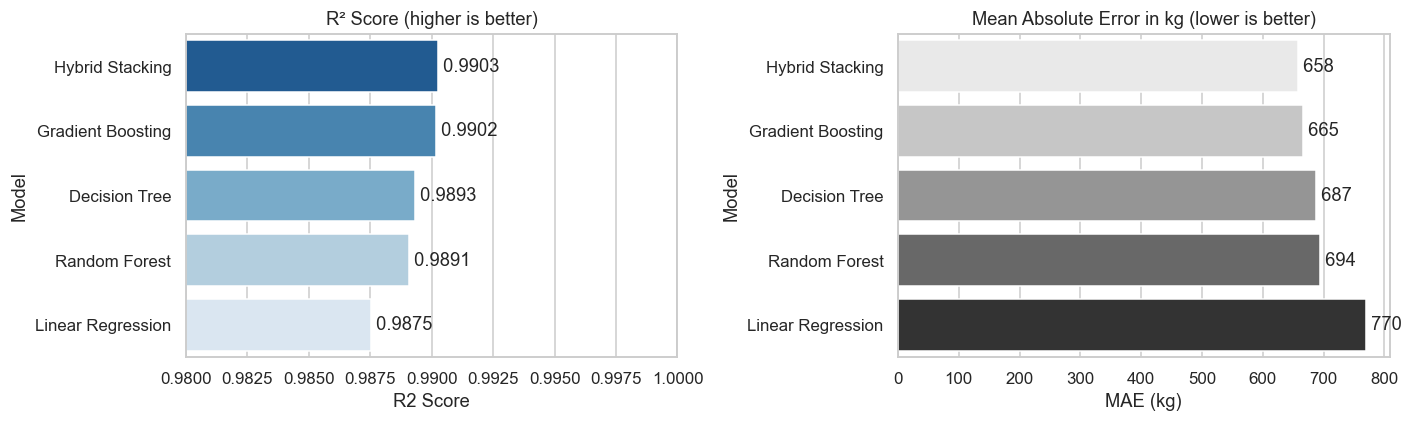

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=results, y="Model", x="R2 Score", ax=ax[0], palette="Blues_r")
ax[0].set_xlim(0.98, 1.0); ax[0].set_title("R² Score (higher is better)")
for i, v in enumerate(results["R2 Score"]):
    ax[0].text(v, i, f" {v:.4f}", va="center")
sns.barplot(data=results, y="Model", x="MAE (kg)", ax=ax[1], palette="Greys")
ax[1].set_title("Mean Absolute Error in kg (lower is better)")
for i, v in enumerate(results["MAE (kg)"]):
    ax[1].text(v, i, f" {v:.0f}", va="center")
plt.tight_layout(); plt.show()

### 8.1 Actual vs Predicted (best model)

Best model: Hybrid Stacking


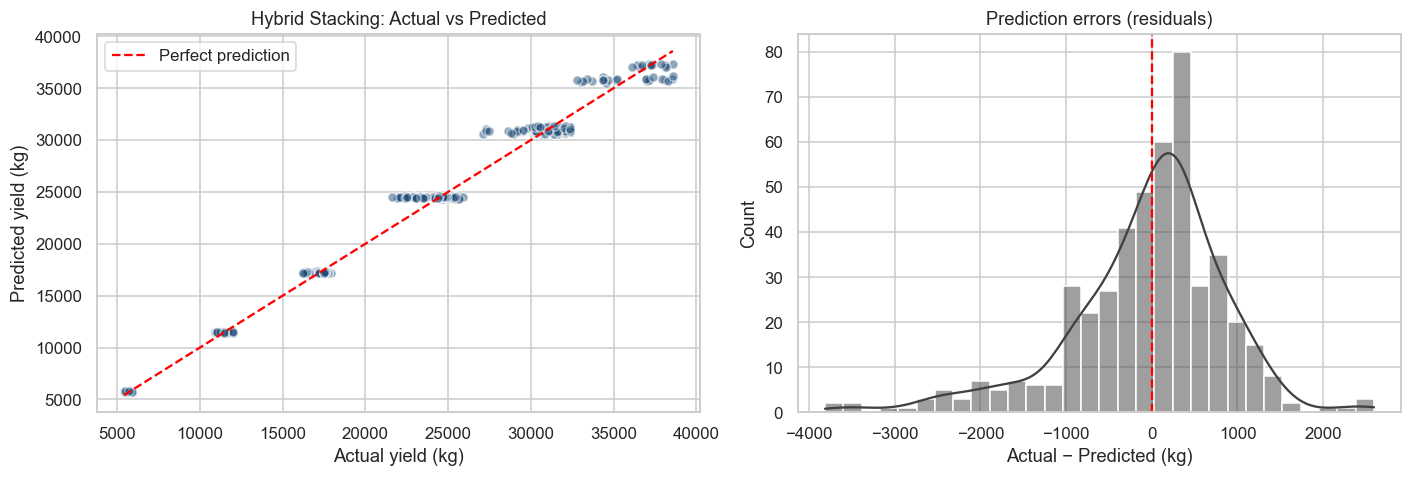

In [23]:
best_name = results.loc[0, "Model"]
best_model = models[best_name]
pred = best_model.predict(X_test)
print("Best model:", best_name)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y_test, pred, alpha=0.5, color="#1f4e79", edgecolor="white")
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "r--", label="Perfect prediction")
ax[0].set_xlabel("Actual yield (kg)"); ax[0].set_ylabel("Predicted yield (kg)")
ax[0].set_title(f"{best_name}: Actual vs Predicted"); ax[0].legend()

residuals = y_test - pred
sns.histplot(residuals, bins=30, kde=True, ax=ax[1], color="#404040")
ax[1].axvline(0, color="red", ls="--")
ax[1].set_title("Prediction errors (residuals)"); ax[1].set_xlabel("Actual − Predicted (kg)")
plt.tight_layout(); plt.show()

 The points sit right on the red line and the errors are centred at 0, so the predictions are accurate and unbiased.

### 8.2 Cross-validation (is the score stable?)
One train/test split could be "lucky". **5-Fold Cross-Validation** splits the data 5 different ways, trains and tests 5 times, and averages the score. This is a fairer comparison of all models.

In [24]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, model in models.items():
    r2s = cross_val_score(model, X, y, cv=kf, scoring="r2")
    maes = -cross_val_score(model, X, y, cv=kf, scoring="neg_mean_absolute_error")
    cv_rows.append({"Model": name, "CV Mean R2": r2s.mean(), "CV Std R2": r2s.std(), "CV Mean MAE (kg)": maes.mean()})
    if model is best_model:
        print(f"{name} R² in each fold:", np.round(r2s, 4))

cv_table = pd.DataFrame(cv_rows).sort_values("CV Mean R2", ascending=False).reset_index(drop=True)
cv_table.style.format({"CV Mean R2": "{:.4f}", "CV Std R2": "{:.4f}", "CV Mean MAE (kg)": "{:.0f}"}) \
        .highlight_max(subset=["CV Mean R2"], color="#cfe0f3").highlight_min(subset=["CV Mean MAE (kg)"], color="#cfe0f3")

Hybrid Stacking R² in each fold: [0.9903 0.9912 0.991  0.9921 0.9935]


,Model,CV Mean R2,CV Std R2,CV Mean MAE (kg)
0,Hybrid Stacking,0.9916,0.0011,611
1,Gradient Boosting,0.9915,0.0011,617
2,Decision Tree,0.9904,0.0009,651
3,Random Forest,0.9901,0.0008,664
4,Linear Regression,0.9887,0.0015,744


 The **Hybrid Stacking** model gives the best score on both the test set and cross-validation, with a very small standard deviation (stable on every fold).

**Why can't we reach R² = 1.00?** Some farms have *exactly the same* conditions (same area, block, variety, soil and nursery) but still got different yields, because of natural field-to-field variation the dataset doesn't record. No model can predict that random part, so R² ≈ 0.99 is very close to the best possible.

### 8.3 Did feature optimization hurt accuracy?
We compare the hybrid model trained on **all 43 original columns** (without Trash) vs our **5 optimized features**.

In [25]:
X_all = pd.get_dummies(df.drop(columns=["Yield"]), dtype=int)
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(X_all, y, test_size=0.2, random_state=42)

from sklearn.base import clone
m_all = clone(hybrid).fit(Xa_tr, ya_tr)
r2_all = r2_score(ya_te, m_all.predict(Xa_te))
r2_opt = r2_score(y_test, models["Hybrid Stacking"].predict(X_test))

pd.DataFrame({
    "Feature set": ["All original columns", "Optimized features"],
    "Number of input columns": [X_all.shape[1], X.shape[1]],
    "Test R²": [round(r2_all, 4), round(r2_opt, 4)],
})

,Feature set,Number of input columns,Test R²
0,All original columns,70,0.9903
1,Optimized features,14,0.9903


 Same accuracy with **far fewer columns**. The model is simpler, faster and easier to explain. This is the benefit of feature optimization.

## Step 9: Key factors influencing paddy yield
We use **Permutation Importance**: shuffle one feature at a time and see how much the model's accuracy drops.
A big drop means the feature is important.

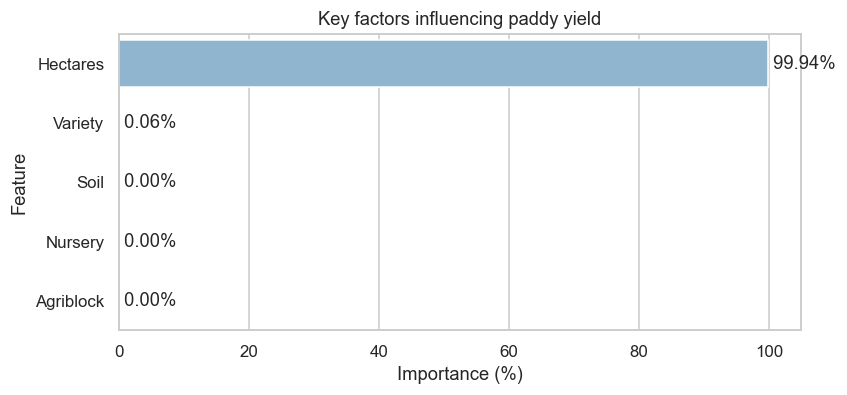

,Importance (%)
Hectares,99.94
Variety,0.06
Soil,0.00
Nursery,0.00
Agriblock,0.00


In [26]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42, scoring="r2")
imp = pd.Series(perm.importances_mean, index=X_test.columns)

# add the one-hot columns back together (e.g. Variety_CO_43 + Variety_ponmani + ... → Variety)
grouped = imp.groupby(lambda c: c.split("_")[0]).sum().sort_values(ascending=False)
grouped = grouped.clip(lower=0)
share = (grouped / grouped.sum() * 100).round(2)

plt.figure(figsize=(8, 3.5))
sns.barplot(x=share.values, y=share.index, palette="Blues_d")
for i, v in enumerate(share.values):
    plt.text(v, i, f" {v:.2f}%", va="center")
plt.title("Key factors influencing paddy yield"); plt.xlabel("Importance (%)"); plt.ylabel("Feature")
plt.show()
share.to_frame("Importance (%)")

Because farm area dominates total yield, we also check **which factors change the yield per hectare** (productivity), using a Random Forest:

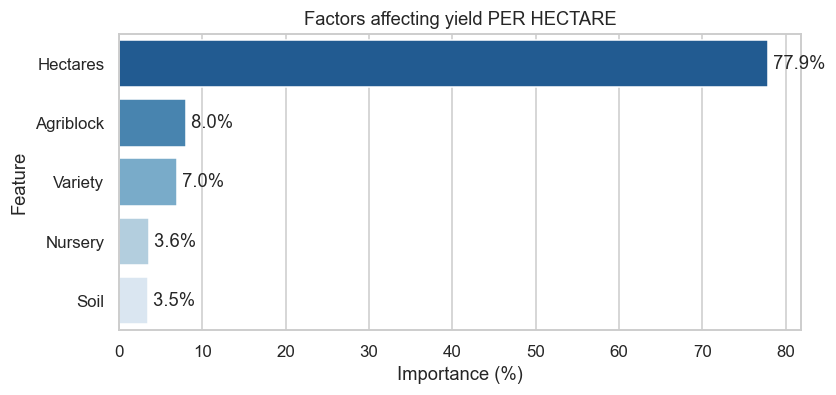

In [27]:
rf_ha = RandomForestRegressor(n_estimators=300, random_state=42)
rf_ha.fit(X, y / df["Hectares"])
imp_ha = pd.Series(rf_ha.feature_importances_, index=X.columns)
imp_ha = imp_ha.groupby(lambda c: c.split("_")[0]).sum().sort_values(ascending=False) * 100

plt.figure(figsize=(8, 3.5))
sns.barplot(x=imp_ha.values, y=imp_ha.index, palette="Blues_r")
for i, v in enumerate(imp_ha.values):
    plt.text(v, i, f" {v:.1f}%", va="center")
plt.title("Factors affecting yield PER HECTARE"); plt.xlabel("Importance (%)"); plt.ylabel("Feature")
plt.show()

**Key findings:**
1. **Farm area (Hectares)** is the main driver of total yield. The fertilizer, seed and pesticide inputs grow with it in the same ratio.
2. **Agriblock (location & weather)** is the next most important factor for productivity per hectare: rainfall, temperature, humidity and wind differ by block.
3. **Variety**, **Nursery type** and **Soil type** have smaller, but real, effects.

## Step 10: Decision support — recommend the best variety
For a farmer's conditions (area, block, soil, nursery), our model **predicts the yield for each of the 3 varieties**.
Then we combine it with the **farmer's preference**:

| Preference | What we rank by |
|---|---|
| `"yield"` | highest predicted yield |
| `"profit"` | highest income = yield × market price |
| `"short_duration"` | best yield among quicker crops |
| `"fine_grain"` | gives priority to fine-grain (premium) rice |

*Duration, grain type and price are general information about these varieties (prices are approximate and can be changed).*

In [28]:
variety_info = pd.DataFrame({
    "Variety":       ["CO_43", "ponmani", "delux ponni"],
    "Duration_days": [135, 155, 140],
    "Grain_type":    ["Medium slender", "Medium bold", "Fine"],
    "Price_Rs_per_kg": [22, 21, 27],
}).set_index("Variety")
variety_info

,Duration_days,Grain_type,Price_Rs_per_kg
Variety,,,
CO_43,135,Medium slender,22
ponmani,155,Medium bold,21
delux ponni,140,Fine,27


In [29]:
def recommend_variety(hectares, agriblock, soil, nursery, preference="profit", model=best_model):
    rows = []
    for variety in variety_info.index:
        farm = pd.DataFrame([{"Hectares": hectares, "Agriblock": agriblock, "Variety": variety,
                              "Soil": soil, "Nursery": nursery}])
        farm = pd.get_dummies(farm, dtype=int).reindex(columns=X.columns, fill_value=0)
        y_pred = model.predict(farm)[0]
        info = variety_info.loc[variety]
        rows.append({
            "Variety": variety,
            "Predicted yield (kg)": round(y_pred),
            "Yield per ha (kg)": round(y_pred / hectares),
            "Duration (days)": info.Duration_days,
            "Grain": info.Grain_type,
            "Est. income (Rs)": round(y_pred * info.Price_Rs_per_kg),
        })
    table = pd.DataFrame(rows)

    # score between 0 and 1 for each criterion, then weight by the farmer's preference
    norm = lambda s: (s - s.min()) / (s.max() - s.min() + 1e-9)
    weights = {   # (yield, income, shortness, fine grain)
        "yield":          (0.7, 0.2, 0.1, 0.0),
        "profit":         (0.2, 0.7, 0.1, 0.0),
        "short_duration": (0.3, 0.2, 0.5, 0.0),
        "fine_grain":     (0.2, 0.3, 0.0, 0.5),
    }[preference]
    table["Score"] = (weights[0] * norm(table["Predicted yield (kg)"])
                    + weights[1] * norm(table["Est. income (Rs)"])
                    + weights[2] * norm(-table["Duration (days)"])
                    + weights[3] * (table["Grain"] == "Fine")).round(3)
    table = table.sort_values("Score", ascending=False).reset_index(drop=True)
    table.index = table.index + 1   # rank 1, 2, 3

    # recommended input plan for this farm (standard dose per hectare × area)
    plan = (dose_per_ha * hectares).round(1).to_frame(f"Amount for {hectares} ha")

    best = table.iloc[0]
    print(f"Recommended variety: {best.Variety.upper()}  (preference = '{preference}')")
    print(f"   Expected yield ≈ {best['Predicted yield (kg)']:,} kg  |  income ≈ Rs {best['Est. income (Rs)']:,}")
    return table, plan

### Example 1: a 4-hectare farm in Cuddalore, clay soil, wet nursery, farmer wants **maximum profit**

In [30]:
table, plan = recommend_variety(4, "Cuddalore", "clay", "wet", preference="profit")
table

Recommended variety: DELUX PONNI  (preference = 'profit')
   Expected yield ≈ 24,412 kg  |  income ≈ Rs 659,113


,Variety,Predicted yield (kg),Yield per ha (kg),Duration (days),Grain,Est. income (Rs),Score
1,delux ponni,24412,6103,140,Fine,659113,0.920
2,CO_43,24439,6110,135,Medium slender,537654,0.425
3,ponmani,24341,6085,155,Medium bold,511169,0.000


**Recommended input plan for this farm** (from the dataset's standard practice):

In [31]:
plan

,Amount for 4 ha
Seedrate,100.0
LP_Mainfield,50.0
Nursery_area,80.0
LP_Nursery,4.0
DAP_20days,160.0
Weed28D_thiobencarb,8.0
Urea_40Days,108.5
Potassh_50Days,41.5
Micronutrients_70Days,60.0
Pest_60Day,2400.0


### Example 2: same farm, but the farmer wants the **highest yield**

In [32]:
table, _ = recommend_variety(4, "Cuddalore", "clay", "wet", preference="yield")
table

Recommended variety: CO_43  (preference = 'yield')
   Expected yield ≈ 24,439 kg  |  income ≈ Rs 537,654


,Variety,Predicted yield (kg),Yield per ha (kg),Duration (days),Grain,Est. income (Rs),Score
1,CO_43,24439,6110,135,Medium slender,537654,0.836
2,delux ponni,24412,6103,140,Fine,659113,0.782
3,ponmani,24341,6085,155,Medium bold,511169,0.000


### Example 3: a 2-hectare farm in Panruti, alluvial soil, dry nursery, farmer wants a **short-duration crop**

In [33]:
table, _ = recommend_variety(2, "Panruti", "alluvial", "dry", preference="short_duration")
table

Recommended variety: CO_43  (preference = 'short_duration')
   Expected yield ≈ 11,470 kg  |  income ≈ Rs 252,341


,Variety,Predicted yield (kg),Yield per ha (kg),Duration (days),Grain,Est. income (Rs),Score
1,CO_43,11470,5735,135,Medium slender,252341,0.838
2,delux ponni,11434,5717,140,Fine,308727,0.746
3,ponmani,11386,5693,155,Medium bold,239102,0.000


## Step 11: Save the trained model

In [34]:
joblib.dump({"model": best_model, "columns": list(X.columns),
             "variety_info": variety_info, "dose_per_ha": dose_per_ha}, "paddy_model.pkl")
print("Model saved as paddy_model.pkl")

Model saved as paddy_model.pkl


## Conclusion

| Goal from problem statement | What we did | Result |
|---|---|---|
| **Data cleaning** | Fixed column names, checked missing values, removed duplicate rows, checked outliers | Clean dataset |
| **Feature-optimized** | Removed the leakage column (Trash), the redundant input columns (correlation > 0.95) and the repeated weather columns | 44 → **5 features**, same accuracy |
| **Key factors** | Permutation importance + Random Forest importance | Farm area ≫ Agriblock (weather) > Variety, Nursery, Soil |
| **Hybrid yield prediction** | Stacking of 2 Gradient Boosting models + Random Forest, combined by Linear Regression | Best model: test R² ≈ 0.99, error ≈ 3% (see Step 8) |
| **Decision support** | Predicts yield for every variety and ranks them by the farmer's preference | Variety recommendation + input plan |

**Future scope:** add live weather data, market prices from government portals, and more varieties and districts.

---
## Bonus: the Hybrid model built from scratch
Want to see what happens *inside* `StackingRegressor`? Open **`Hybrid_Model_From_Scratch.ipynb`**.
There we hand-code every piece using only NumPy (train/test split, metrics, Linear Regression, Decision Tree, Random Forest, Gradient Boosting, K-Fold and Stacking), explain each step in simple words, and show that our version matches scikit-learn's results (about 0.1% average difference in predictions).